# Metin, ses ve görsel etkileşim örnekleri

Öğrenci, çalışmak istediği beceriyi yazarak, kısa bir ses dosyasıyla veya
yazı içeren görselle ifade eder. Üç giriş aynı beceri belirleme ve mevcut
soru önerme akışına gider. İstek bir ölçme sorusuna cevap değildir;
öğrencinin başarı geçmişine eklenmez.

Bu defterde ses gerçekten çözümlenir, görseldeki yazı gerçekten okunur.
Önceki 20 adımlık örnek oturumun sonundaki 25 cevap sabit bağlamdır.

In [1]:
from pathlib import Path
import inspect
import json
import os
import subprocess
import sys
import pandas as pd
from IPython.display import display, Audio, Image, Code

ROOT = Path.cwd().resolve()
if not (ROOT / "src/kt_project").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/kt_project").exists()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("HF_HOME", str(ROOT / ".runtime/huggingface"))
os.environ.setdefault("CUDA_CACHE_PATH", str(ROOT / ".runtime/cuda"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".runtime/matplotlib"))

def read_json(name):
    return json.loads((ROOT / name).read_text(encoding="utf-8"))

def run_script(name):
    process = subprocess.run([sys.executable, str(ROOT / "scripts" / name)],
                             cwd=ROOT, capture_output=True, text=True,
                             encoding="utf-8", errors="replace")
    print(process.stdout)
    if process.returncode:
        print(process.stderr)
    process.check_returncode()

import torch
from kt_project.intent import train_intent_model
from kt_project.interactions import InteractionService
from kt_project.media import SpeechReader, read_image
torch.set_num_threads(4)
if not (ROOT / "outputs/interactions/intent_model.joblib").exists():
    train_intent_model(ROOT)
if not (ROOT / "data/models/whisper-base/model.safetensors").exists():
    raise FileNotFoundError("Önce scripts/download_interaction_model.py ile açık ses modelini indirin.")
if not (ROOT / "outputs/interactions/examples.json").exists():
    run_script("run_interaction_examples.py")
metrics = read_json("outputs/interactions/intent_metrics.json")
examples = read_json("outputs/interactions/examples.json")
service = InteractionService(ROOT)
print("Öğrenci bağlamı:", service.snapshot.stop-service.snapshot.start, "mevcut cevap")

Öğrenci bağlamı: 25 mevcut cevap


## Beceri isteğinin öğrenilmesi ve kapsam sınırı

Üç beceri: tam sayılarda toplama ve çıkarma, pozitif ondalık sayılarda
toplama ve çıkarma, kesirlerde toplama ve çıkarma. Bunlar mevcut ASSIST
becerileridir. Karakter TF IDF ve lojistik regresyon 48 yazılmış eğitim
ifadesinden öğrenir. 20 doğrulama ifadesi kabul eşiği seçimine ayrılır.
20 başka ifade küçük işlev kontrolüdür. Gerçek öğrenci beyanları değildir.

Kapsam kuralları çoklu beceri, belirsiz konu ve desteklenmeyen işlemde
açıklama ister. Düşük sınıflandırma skorunda da konu zorla seçilmez.
Bu skor öğrenci başarı yüzdesi veya kalibre edilmiş güven değildir.

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char_wb', lowercase=False,
                                 ngram_range=(3, 5),
                                 preprocessor=<function normalize_text at 0x0000028B9C754400>,
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(C=8.0, max_iter=1000, random_state=2026))])


,threshold,validation_macro_f1
0,0.40,1.000000
1,0.45,1.000000
2,0.50,1.000000
3,0.55,1.000000
4,0.60,1.000000
5,0.65,1.000000
6,0.70,0.949580
7,0.75,0.853383
8,0.80,0.662771


training_records      48.00000
validation_records    20.00000
test_records          20.00000
threshold              0.65000
test_accuracy          0.95000
test_macro_f1          0.94958
dtype: float64

,id,text,actual,predicted
0,integers_test_01,Eksi ve artı tam sayılarda toplama pratiği yap...,integers,integers
1,integers_test_02,Tam sayıların çıkarma işlemi için alıştırma seç.,integers,integers
2,integers_test_03,Negatif tam sayılarda toplama konusunu pekişti...,integers,integers
3,integers_test_04,Tam sayılarla çıkarma işlemini tekrar etmek is...,integers,out_of_scope
4,decimals_test_01,Virgüllü sayıların toplama işlemini pekiştirelim.,decimals,decimals
5,decimals_test_02,Ondalık sayılarla çıkarma alıştırması seçer mi...,decimals,decimals
6,decimals_test_03,Pozitif ondalıklarla toplama konusunu yeniden ...,decimals,decimals
7,decimals_test_04,Ondalık sayı çıkarma işlemi için yardım istiyo...,decimals,decimals
8,fractions_test_01,Farklı paydalı kesirlerle toplama örneği çözelim.,fractions,fractions
9,fractions_test_02,Kesirlerin çıkarma işlemini pekiştirelim.,fractions,fractions


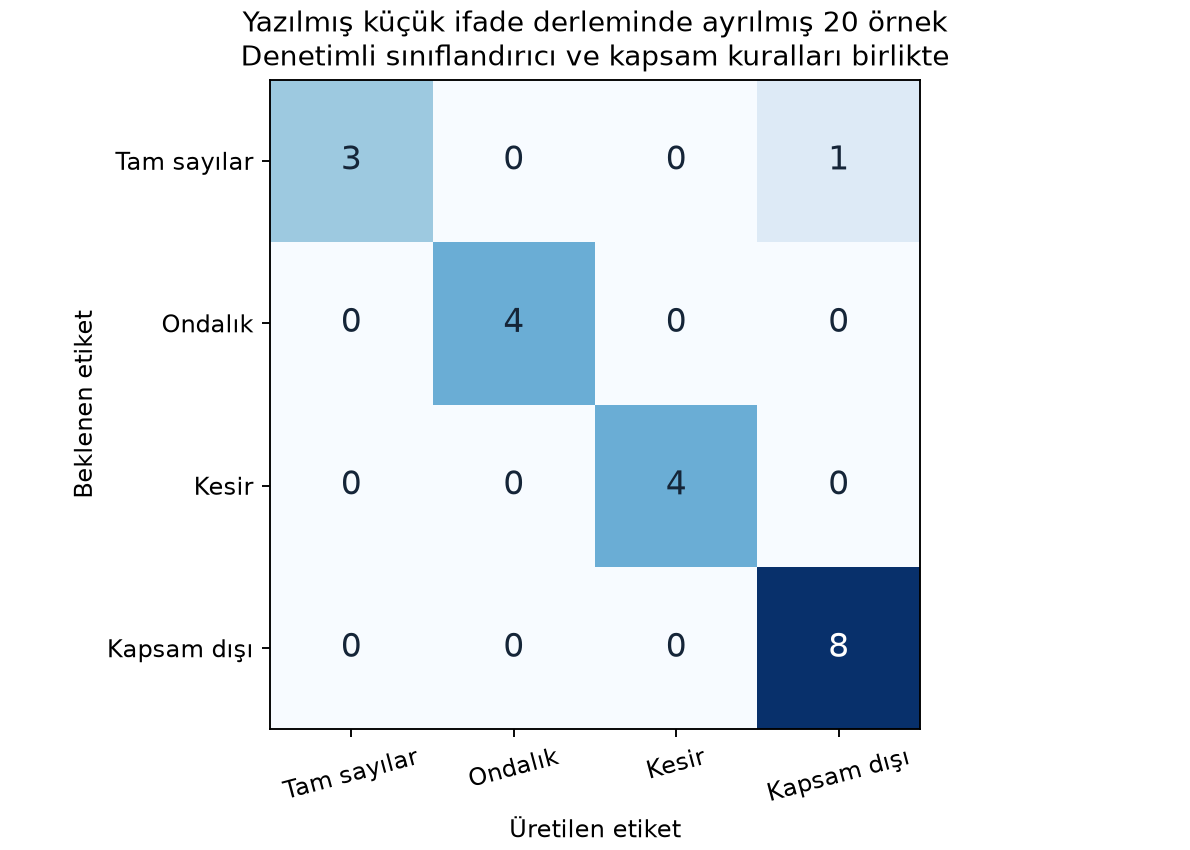

In [2]:
print(service.intent.pipeline)
display(pd.DataFrame(metrics["threshold_candidates"]))
display(pd.Series({key: metrics[key] for key in [
    "training_records", "validation_records", "test_records", "threshold", "test_accuracy", "test_macro_f1"]}))
display(pd.DataFrame(metrics["test_predictions"]))
if not (ROOT / "outputs/validation/interaction_integrity.json").exists():
    run_script("audit_interaction_examples.py")
if not (ROOT / "outputs/figures/interaction_intent_confusion.png").exists():
    run_script("write_interaction_report.py")
display(Image(filename=str(ROOT / "outputs/figures/interaction_intent_confusion.png")))

Küçük ayrılmış derlemde 20 örneğin 19'u beklenen etiketi aldı. Kapsam içi
bir tam sayı isteği düşük skor nedeniyle açıklama isteme sonucuna gitti;
hatayı koruyoruz. Bu yazılmış derlemdeki oran, gerçek öğrencilerdeki veya
ses ve görsel modellerindeki başarı oranı olarak yorumlanmaz.

## Metin girişini çalıştırma

Dosyadaki metin okunur; öğrenci isteği mevcut beceriye bağlanır.
Öneri mevcut soru kimliğini ve model tahminini içerir.

In [3]:
live_examples = []
text = (ROOT / "data/interactions/text_fractions.txt").read_text(encoding="utf-8")
text_result = service.respond(text)
live_examples.append({"modality": "text", **text_result})
print("Öğrenci:", text)
print("Öğretici:", text_result["reply"])
print("Gerekçe:", text_result["recommendation"]["reason"])
print("Geçmiş değişmedi:", text_result["history_unchanged"])

Öğrenci: Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.
Öğretici: İsteğini kesirlerde toplama ve çıkarma olarak algıladım. Mevcut sorulardan 86320 kimlikli soruyu öneriyorum. Bu soru için tahmini doğru cevap olasılığı %65.0.
Gerekçe: Kesirlerde toplama ve çıkarma: öğrencinin ifade ettiği beceri önceliklendirildi; sabit referans başarı tahmini %57.6. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %65.0, hedef %65.
Geçmiş değişmedi: True


## Ses girişini çalıştırma

Bu ses Microsoft Tolga ile üretilmiş Türkçe sentetik konuşmadır. WAV
örnekleri gerçekten okunur ve 16000 Hz hızına dönüştürülür. Önceden
eğitilmiş Whisper base sabit sürümde, Türkçe yazıya dökme göreviyle çalışır.
Model bu projede yeniden eğitilmez. Ses oynatıcıdan dinlenebilir.

In [4]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: C:\Users\unalm\OneDrive\Belgeler\ChatGPT\Prompt tuning for Knowledge tracing\.venv\Scripts\python.exe -m pip install --upgrade pip


In [5]:
display(Code(inspect.getsource(SpeechReader.read), language="python"))
audio_path = ROOT / "data/interactions/audio_decimals.wav"
display(Audio(filename=str(audio_path)))
speech = SpeechReader(ROOT)
recognized_audio = speech.read(audio_path)
audio_result = service.respond(recognized_audio["text"])
live_examples.append({"modality": "audio", "recognition": recognized_audio, **audio_result})
print("Gerçek ASR çıktısı:", recognized_audio["text"])
print("Öğretici:", audio_result["reply"])
print("Örnekleme bilgileri:", {k: recognized_audio[k] for k in ["source_sample_rate", "model_sample_rate", "duration_seconds"]})

def read(self, path):
        import torch
        samples, metadata = load_audio(path, self.config["sample_rate"])
        features = self.processor(samples, sampling_rate=self.config["sample_rate"],
                                  return_tensors="pt", return_attention_mask=True)
        with torch.inference_mode():
            ids = self.model.generate(input_features=features.input_features.to(self.device),
                                      attention_mask=features.attention_mask.to(self.device),
                                      language=self.config["asr_language"], task="transcribe",
                                      do_sample=False, num_beams=1, max_new_tokens=96)
        return {"text": self.processor.batch_decode(ids, skip_special_tokens=True)[0].strip(),
                "engine": self.config["asr_model"], "revision": self.config["asr_revision"],
                "language": self.config["asr_language"], **metadata}

Gerçek ASR çıktısı: 10 dalık sayılarda toplama ve çıkarmak çalışmak istiyorum.
Öğretici: İsteğini pozitif ondalık sayılarda toplama ve çıkarma olarak algıladım. Mevcut sorulardan 73161 kimlikli soruyu öneriyorum. Bu soru için tahmini doğru cevap olasılığı %65.5.
Örnekleme bilgileri: {'source_sample_rate': 16000, 'model_sample_rate': 16000, 'duration_seconds': 4.065}


Sesin beklenen cümlesi “Ondalık sayılarda toplama ve çıkarma çalışmak
istiyorum.” ifadesidir. Gerçek ASR çıktısındaki sözcük hataları düzeltilmez.
Beceri doğru seçilmiş olsa da bu, konuşmanın eksiksiz tanındığı anlamına
gelmez. Kullanıcı tanınan metni görerek yeni bir girişle düzeltebilir.

## Görsel girişini çalıştırma

Türkçe yazı içeren PNG, Windows OCR ile gerçekten okunur. Bu örnek
basılı yazı tanımadır; el yazısı veya matematik şekli çözümleme içermez.

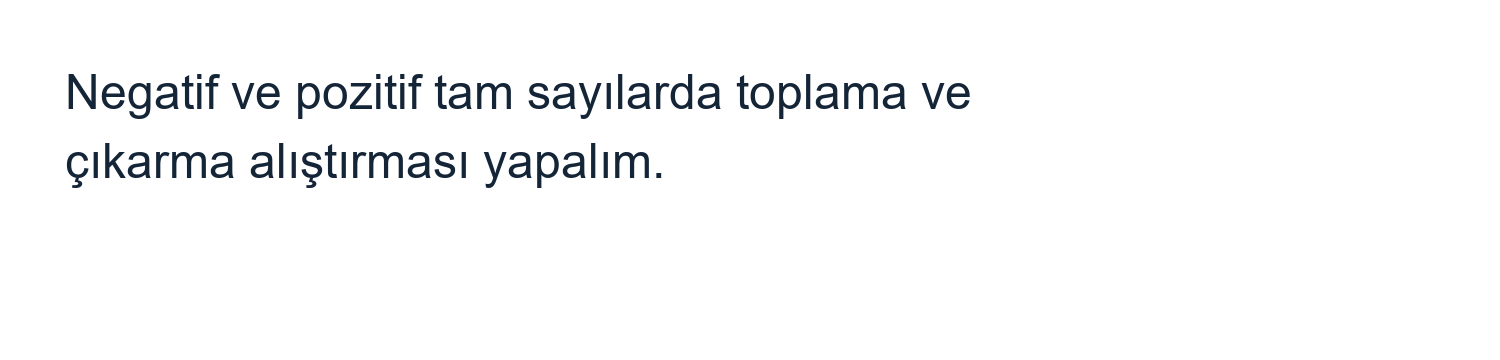

Gerçek OCR çıktısı: Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırması yapalım.
OCR motoru ve dil: Windows.Media.Ocr.OcrEngine tr
Öğretici: İsteğini tam sayılarda toplama ve çıkarma olarak algıladım. Mevcut sorulardan 53833 kimlikli soruyu öneriyorum. Bu soru için tahmini doğru cevap olasılığı %64.8.


6157

In [6]:
image_path = ROOT / "data/interactions/image_integers.png"
display(Image(filename=str(image_path), width=900))
recognized_image = read_image(ROOT, image_path)
image_result = service.respond(recognized_image["text"])
live_examples.append({"modality": "image", "recognition": recognized_image, **image_result})
print("Gerçek OCR çıktısı:", recognized_image["text"])
print("OCR motoru ve dil:", recognized_image["engine"], recognized_image["language"])
print("Öğretici:", image_result["reply"])
(ROOT / "outputs/interactions/notebook_live_examples.json").write_text(
    json.dumps(live_examples, ensure_ascii=False, indent=2), encoding="utf-8")

## Dokuz kontrollü girdinin çıktıları

Aynı üç istek üç giriş türünde hazırlanmıştır. Beklenen içerik yalnızca
tanıma tamamlandıktan sonra ölçümde kullanılır. Ses veya OCR işlevlerine
beklenen metin verilmez. Sözcük hata oranı harf, noktalama ve Türkçe
karakter normalleştirmesinden sonra hesaplanır; ham çıktılar da saklanır.

In [7]:
comparison = pd.DataFrame([{
    "Örnek": row["sample_id"], "Beklenen metin": row["evaluation"]["expected_text"],
    "Gerçek tanınan metin": row["recognized_text"],
    "Sözcük hata oranı %": 100*row["evaluation"]["normalized_word_error_rate"],
    "Beceri": row["intent"]["label"], "Beklenen beceri seçildi": row["evaluation"]["label_correct"],
    "Önerilen mevcut soru": row["recommendation"]["original_problem_id"] if row["recommendation"] else None,
} for row in examples["results"]])
with pd.option_context("display.max_colwidth", 100):
    display(comparison.round(2))
display(pd.DataFrame(examples["modality_summary"]))

,Örnek,Beklenen metin,Gerçek tanınan metin,Sözcük hata oranı %,Beceri,Beklenen beceri seçildi,Önerilen mevcut soru
0,text_integers,Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırması yapalım.,Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırması yapalım.,0.00,integers,True,53833
1,text_decimals,Ondalık sayılarda toplama ve çıkarma çalışmak istiyorum.,Ondalık sayılarda toplama ve çıkarma çalışmak istiyorum.,0.00,decimals,True,73161
2,text_fractions,Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.,Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.,0.00,fractions,True,86320
3,audio_integers,Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırması yapalım.,Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırmasın yapalım.,10.00,integers,True,53833
4,audio_decimals,Ondalık sayılarda toplama ve çıkarma çalışmak istiyorum.,10 dalık sayılarda toplama ve çıkarmak çalışmak istiyorum.,42.86,decimals,True,73161
5,audio_fractions,Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.,Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.,0.00,fractions,True,86320
6,image_integers,Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırması yapalım.,Negatif ve pozitif tam sayılarda toplama ve çıkarma alıştırması yapalım.,0.00,integers,True,53833
7,image_decimals,Ondalık sayılarda toplama ve çıkarma çalışmak istiyorum.,Ondalık sayılarda toplama ve çıkarma çalışmak istiyorum.,0.00,decimals,True,73161
8,image_fractions,Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.,Paydaları farklı kesirlerde toplama ve çıkarma yaparken zorlanıyorum.,0.00,fractions,True,86320


,modality,examples,correct_skill_routes,mean_normalized_word_error_rate,pooled_normalized_word_error_rate
0,text,3,3,0.00000,0.00
1,audio,3,3,0.17619,0.16
2,image,3,3,0.00000,0.00


Üç sentetik ses ve üç basılı görsel, genel ASR veya OCR değerlendirmesi
değildir. Dokuz küçük girdinin doğru beceriye bağlanması ile sözcüklerin
hatasız tanınması ayrı sonuçlardır. Yeni soru metni veya soru kimliği
üretilmez; kaynakta özgün soru metni bulunmadığı için kimlik gösterilir.

## Belirsiz ve kapsam dışı isteklere yanıt

In [8]:
for text in ["Matematik çalışmak istiyorum.", "Kesirlerde çarpma yapmak istiyorum.",
             "Kesirler ve tam sayılarda toplama çalışalım."]:
    result = service.respond(text)
    print("Öğrenci:", text)
    print("Öğretici:", result["reply"])
    print("Öneri üretildi:", result["recommendation"] is not None)
    print()

Öğrenci: Matematik çalışmak istiyorum.
Öğretici: Lütfen beceriyi ve toplama veya çıkarma işlemini açıkça belirt.
Öneri üretildi: False

Öğrenci: Kesirlerde çarpma yapmak istiyorum.
Öğretici: Bu örnek yalnızca üç beceride toplama ve çıkarma isteklerini kapsıyor.
Öneri üretildi: False

Öğrenci: Kesirler ve tam sayılarda toplama çalışalım.
Öğretici: Birden fazla beceri belirttin; önce hangisini çalışmak istediğini seçelim.
Öneri üretildi: False



## Kendi kısa girdini deneme

`input_type` için `text`, `audio` veya `image` seçip bu hücreyi çalıştırın.
Metinde `my_text`, dosyada `my_path` kullanılır. Ses 16 bit PCM WAV,
0,2–30 saniye olmalı. OCR için Windows Türkçe tanıma dili kurulmalıdır.
Tanınan metin de sonuçla birlikte gösterilir.

In [9]:
input_type = "text"
my_text = "Kesirlerde toplama yapmak istiyorum."
my_path = ROOT / "data/interactions/audio_fractions.wav"

if input_type == "text":
    recognized = {"text": my_text}
elif input_type == "audio":
    recognized = speech.read(my_path)
elif input_type == "image":
    recognized = read_image(ROOT, my_path)
else:
    raise ValueError("Giriş türü text, audio veya image olmalı.")
result = service.respond(recognized["text"])
print("Alınan metin:", recognized["text"])
print("Öğretici:", result["reply"])
print("Cevap geçmişi değişmedi:", result["history_unchanged"])

Alınan metin: Kesirlerde toplama yapmak istiyorum.
Öğretici: İsteğini kesirlerde toplama ve çıkarma olarak algıladım. Mevcut sorulardan 86320 kimlikli soruyu öneriyorum. Bu soru için tahmini doğru cevap olasılığı %65.0.
Cevap geçmişi değişmedi: True


## Güvenilirlik denetimi

Öğrenci geçmişi, model ağırlıkları, davranış grupları ve referanslar
sabit kalır. Metin, ses ve görsel verileri LKM içine verilmez; yalnızca
çalışma isteğinin hangi mevcut beceriye ait olduğunu belirler. Öneri
etkisini ölçen yeni bir öğrenme deneyi yapılmamıştır.

Aşağıdaki denetim dosya özetlerini, hata ölçülerini ve önerilerin mevcut
eğitim sorularına ait olduğunu yeniden kontrol eder. Ardından proje
testleri çalıştırılır ve çıktısı saklanır.

In [10]:
run_script("audit_interaction_examples.py")
display(pd.Series(read_json("outputs/validation/interaction_integrity.json")))
process = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                         cwd=ROOT, capture_output=True, text=True, encoding="utf-8", errors="replace")
output = process.stdout + process.stderr
(ROOT / "outputs/validation/interaction_test_output.txt").write_text(output, encoding="utf-8")
print(output)
process.check_returncode()

{"input_hashes_verified": true, "asr_weights_and_revision_verified": true, "corpus_and_demo_expressions_disjoint": true, "test_metrics_recomputed": true, "recognition_error_metrics_recomputed": true, "routing_from_actual_recognized_text_verified": true, "recommendations_are_known_training_questions": true, "requests_do_not_append_answers": true, "unchanged_state_hashes_verified": true, "main_experiment_sources_unchanged": true, "examples_checked": 9}



input_hashes_verified                           True
asr_weights_and_revision_verified               True
corpus_and_demo_expressions_disjoint            True
test_metrics_recomputed                         True
recognition_error_metrics_recomputed            True
routing_from_actual_recognized_text_verified    True
recommendations_are_known_training_questions    True
requests_do_not_append_answers                  True
unchanged_state_hashes_verified                 True
main_experiment_sources_unchanged               True
examples_checked                                   9
dtype: object

test_multiple_skills_are_one_event_and_conflicts_are_excluded (test_data_preparation.PreparationTests.test_multiple_skills_are_one_event_and_conflicts_are_excluded) ... ok
test_test_answers_do_not_change_training_difficulty_or_references (test_data_preparation.PreparationTests.test_test_answers_do_not_change_training_difficulty_or_references) ... ok
test_missing_or_duplicated_run_is_rejected (test_experiment_results.ExperimentResultsTests.test_missing_or_duplicated_run_is_rejected) ... ok
test_prototype_selection_is_unchanged_when_test_scores_change (test_experiment_results.ExperimentResultsTests.test_prototype_selection_is_unchanged_when_test_scores_change) ... ok
test_sample_standard_deviation_uses_three_independent_seeds (test_experiment_results.ExperimentResultsTests.test_sample_standard_deviation_uses_three_independent_seeds) ... ok
test_complete_fixture_is_verified (test_experiment_results.SavedExperimentAuditTests.test_complete_fixture_is_verified) ... ok
test_nonfinite_saved_we